# Análise das vendas

Vamos entender o faturamento e a rentabilidade das vendas: quanto vendemos, qual a margem, e como isso varia por produto, categoria, região e canal de venda ao longo do tempo.

## Carregando os dados

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

In [2]:
COR_PRIMARIA   = "#0072B2"
COR_SECUNDARIA = "#94A3B8"
COR_DESTAQUE   = "#E69F00"
PALETA = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"]

plt.rcParams.update({
    "figure.figsize": (10, 6),
    "figure.dpi": 110,
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.prop_cycle": plt.cycler(color=PALETA),
})


In [3]:
df = pd.read_csv("dados/vendas.csv")
df.shape

(5000, 8)

In [4]:
df.dtypes.to_frame("tipo")

,tipo
data,str
produto,str
categoria,str
regiao,str
quantidade,int64
preco_unitario,float64
custo_unitario,float64
canal_venda,str


In [5]:
df.head(3)

,data,produto,categoria,regiao,quantidade,preco_unitario,custo_unitario,canal_venda
0,2025-01-01,Mouse,Acessórios,Centro-Oeste,5,52.97,30.53,Online
1,2025-01-01,Monitor,Eletrônicos,Sul,7,1118.13,765.68,Loja física
2,2025-01-01,Tablet,Eletrônicos,Centro-Oeste,6,1611.59,959.28,Marketplace


## Os dados têm buracos ou repetições?
Antes de calcular qualquer coisa, confere se falta valor em alguma coluna e se não há linha duplicada.

In [6]:
df.isna().sum().to_frame("faltando"), df.duplicated().sum()


(                faltando
 data                   0
 produto                0
 categoria              0
 regiao               154
 quantidade             0
 preco_unitario         0
 custo_unitario         0
 canal_venda            0,
 np.int64(0))

**Resultado:** não há linhas duplicadas. Só a coluna `regiao` tem falha: 154 vendas (3%) sem região informada. É pouco pra descartar — vamos manter essas vendas (elas continuam valendo pro faturamento total) e marcar a região como "Não informado", só excluindo-as quando a pergunta for especificamente sobre região.

In [7]:
df["data"] = pd.to_datetime(df["data"])
df["regiao"] = df["regiao"].fillna("Não informado")
df[["data", "regiao"]].dtypes

data      datetime64[us]
regiao               str
dtype: object

## Qual foi o faturamento, o custo e a margem no período?
Primeiro calcula receita e custo por venda (quantidade × preço/custo unitário), e a margem — é o que vamos usar daqui pra frente.


In [8]:
def reais(v):
    return f"R$ {v:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")

df["receita"] = df["quantidade"] * df["preco_unitario"]
df["custo"] = df["quantidade"] * df["custo_unitario"]
df["margem"] = df["receita"] - df["custo"]
df[["receita", "custo", "margem"]].head(3)


,receita,custo,margem
0,264.85,152.65,112.20
1,7826.91,5359.76,2467.15
2,9669.54,5755.68,3913.86


In [9]:
total_receita, total_custo, total_margem = df[["receita", "custo", "margem"]].sum()
margem_pct = total_margem / total_receita
print("Faturamento:", reais(total_receita))
print("Custo:      ", reais(total_custo))
print("Margem:     ", reais(total_margem), f"({margem_pct:.1%})")


Faturamento: R$ 25.016.139,62
Custo:       R$ 15.926.125,02
Margem:      R$ 9.090.014,60 (36.3%)


**Resultado:** no período, o negócio faturou `R$ 25.016.139,62` e teve margem de `R$ 9.090.014,60` — ou seja, de cada R$ 1 vendido, `R$ 0,36` sobra depois de cobrir o custo do produto. É uma margem bruta saudável; vale ver se ela é parecida em todos os produtos/canais ou se tem muita variação escondida por trás dessa média.


## Como o faturamento evolui mês a mês?


In [10]:
faturamento_mensal = df.set_index("data").resample("ME")["receita"].sum()
faturamento_mensal.to_frame("receita")


,receita
data,
2025-01-31,1108186.68
2025-02-28,1341894.08
2025-03-31,1740646.35
2025-04-30,1715094.81
2025-05-31,1896748.57
2025-06-30,1681848.24
2025-07-31,1991033.83
2025-08-31,2073660.68
2025-09-30,2108096.79


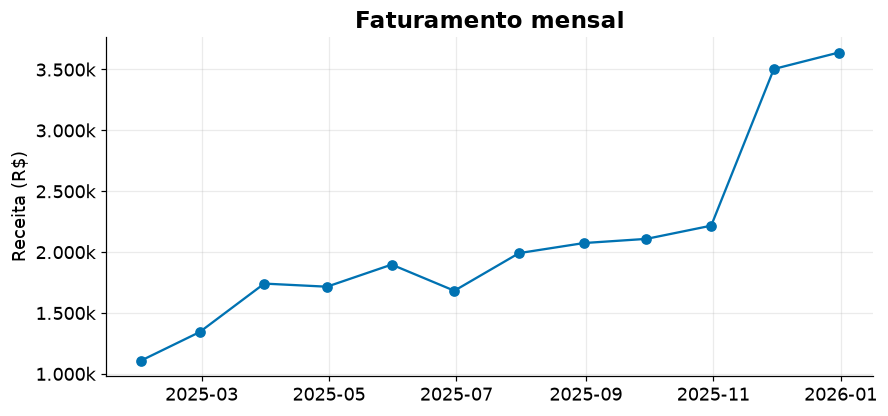

In [11]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(faturamento_mensal.index, faturamento_mensal.values, marker="o", color=COR_PRIMARIA)
ax.set_title("Faturamento mensal")
ax.set_ylabel("Receita (R$)")
ax.yaxis.set_major_formatter(lambda v, _: f"{v/1000:,.0f}k".replace(",", "."))
plt.show()


**Resultado:** o faturamento cresce ao longo do ano e dá um salto forte em novembro e dezembro (quase o dobro dos meses do meio do ano). Não é artefato de mês incompleto — o ano tem os 12 meses completos (jan a dez/2025) — e o salto também aparece no número de vendas (654 e 745 vendas, contra ~350-430 nos meses anteriores), não só no valor: é mais gente comprando, consistente com Black Friday e Natal.


## Quais categorias faturam mais, e quais têm a melhor margem?
Faturamento alto não é o mesmo que ser rentável — uma categoria pode vender muito e sobrar pouco.


In [12]:
por_categoria = df.groupby("categoria")[["receita", "custo", "margem"]].sum()
por_categoria["margem_pct"] = por_categoria["margem"] / por_categoria["receita"]
por_categoria.sort_values("receita", ascending=False)


,receita,custo,margem,margem_pct
categoria,,,,
Eletrônicos,17113195.00,10901644.34,6211550.66,0.362968
Móveis,5937122.22,3769359.85,2167762.37,0.365120
Acessórios,1965822.40,1255120.83,710701.57,0.361529


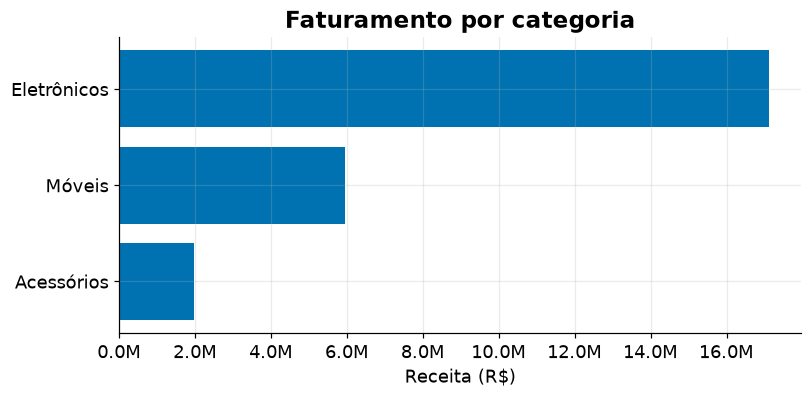

In [13]:
ordenado = por_categoria.sort_values("receita")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(ordenado.index, ordenado["receita"], color=COR_PRIMARIA)
ax.set_title("Faturamento por categoria")
ax.set_xlabel("Receita (R$)")
ax.xaxis.set_major_formatter(lambda v, _: f"{v/1e6:,.1f}M".replace(",", "."))
plt.show()


**Resultado:** `Eletrônicos` domina o faturamento (`R$ 17,1M`, 68% do total), bem à frente de `Móveis` (`R$ 5,9M`) e `Acessórios` (`R$ 2,0M`) — mas a margem percentual é praticamente igual nas três (~36%). Ou seja, não é que uma categoria seja mais rentável que a outra; Eletrônicos fatura mais porque vende muito mais, não porque dá mais lucro por real vendido.


## Faturamento e margem por região


In [14]:
por_regiao = df.groupby("regiao")[["receita", "margem"]].sum()
por_regiao["margem_pct"] = por_regiao["margem"] / por_regiao["receita"]
por_regiao.sort_values("receita", ascending=False)


,receita,margem,margem_pct
regiao,,,
Sudeste,9827937.32,3565847.92,0.362828
Sul,4380944.08,1589874.02,0.362907
Nordeste,4140642.33,1505389.06,0.363564
Centro-Oeste,3086274.60,1126570.31,0.365026
Norte,2854711.86,1038881.70,0.363918
Não informado,725629.43,263451.59,0.363066


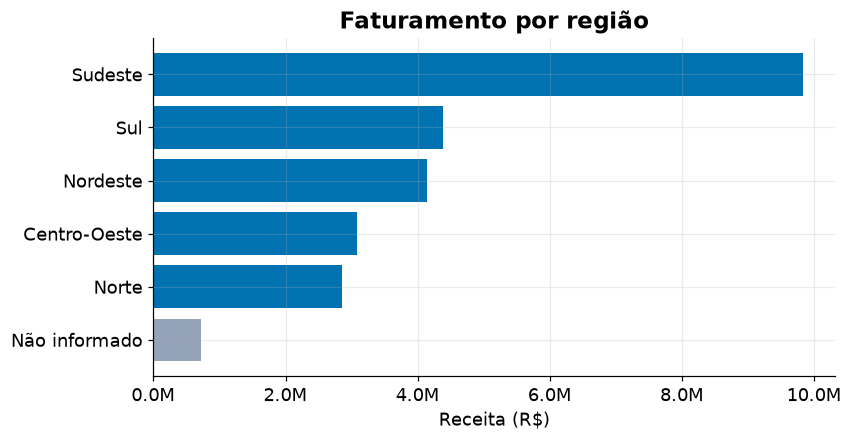

In [15]:
ordenado_r = por_regiao.sort_values("receita")
fig, ax = plt.subplots(figsize=(8, 4))
cores = [COR_SECUNDARIA if r == "Não informado" else COR_PRIMARIA for r in ordenado_r.index]
ax.barh(ordenado_r.index, ordenado_r["receita"], color=cores)
ax.set_title("Faturamento por região")
ax.set_xlabel("Receita (R$)")
ax.xaxis.set_major_formatter(lambda v, _: f"{v/1e6:,.1f}M".replace(",", "."))
plt.show()


**Resultado:** o Sudeste sozinho responde por 39% do faturamento (`R$ 9,8M`), quase o dobro do segundo colocado (Sul, `R$ 4,4M`). De novo, a margem é praticamente igual em todas as regiões (~36%) — o padrão se repete: a diferença entre regiões é de volume de venda, não de rentabilidade. As vendas sem região (`R$ 0,7M`, 2,9%) batem com os 154 registros faltantes já identificados.


## Algum canal de venda é mais rentável que os outros?


In [16]:
por_canal = df.groupby("canal_venda")[["receita", "margem"]].sum()
por_canal["margem_pct"] = por_canal["margem"] / por_canal["receita"]
por_canal.sort_values("receita", ascending=False)


,receita,margem,margem_pct
canal_venda,,,
Online,11155638.64,4056599.06,0.363637
Loja física,7982486.44,2903488.13,0.363732
Marketplace,5878014.54,2129927.41,0.362355


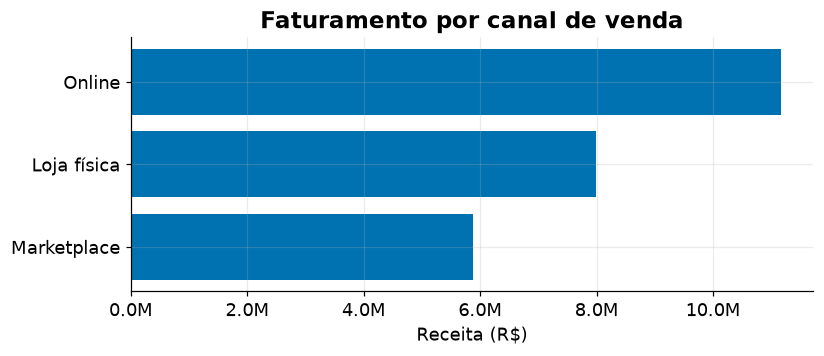

In [17]:
ordenado_c = por_canal.sort_values("receita")
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(ordenado_c.index, ordenado_c["receita"], color=COR_PRIMARIA)
ax.set_title("Faturamento por canal de venda")
ax.set_xlabel("Receita (R$)")
ax.xaxis.set_major_formatter(lambda v, _: f"{v/1e6:,.1f}M".replace(",", "."))
plt.show()


**Resultado:** `Online` é o canal que mais fatura (`R$ 11,2M`, 45%), à frente de `Loja física` (`R$ 8,0M`) e `Marketplace` (`R$ 5,9M`) — e, mais uma vez, a margem é a mesma nos três (~36%). Esse padrão já apareceu em categoria e região: a margem percentual deste negócio é praticamente constante, não importa como você corta o dado. O que muda de verdade é só o volume — então, pra crescer margem em R$, a alavanca é vender mais, não mudar o mix de canal/categoria/região.


## Quais produtos específicos mais faturam?
São só 12 produtos — dá pra ver o ranking completo, não só por categoria.


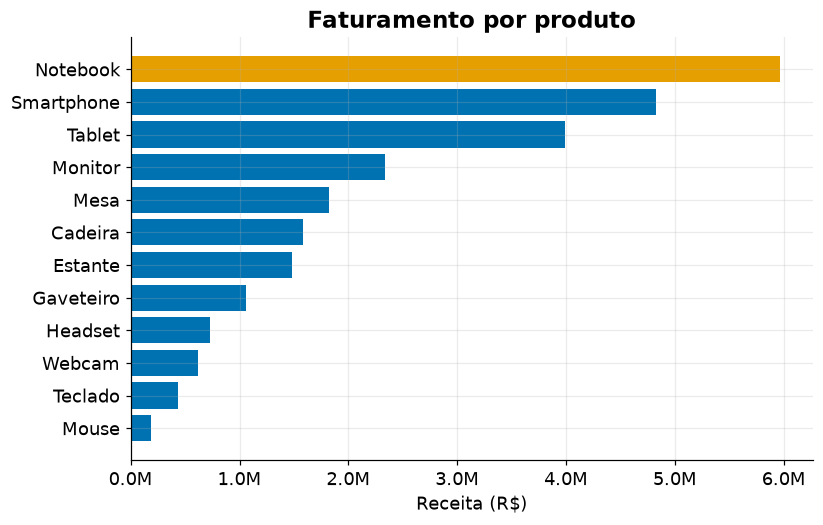

In [18]:
por_produto = df.groupby("produto")["receita"].sum().sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
cores = [COR_DESTAQUE if p == por_produto.idxmax() else COR_PRIMARIA for p in por_produto.index]
ax.barh(por_produto.index, por_produto.values, color=cores)
ax.set_title("Faturamento por produto")
ax.set_xlabel("Receita (R$)")
ax.xaxis.set_major_formatter(lambda v, _: f"{v/1e6:,.1f}M".replace(",", "."))
plt.show()


**Resultado:** `Notebook` é o produto que mais fatura sozinho (`R$ 6,0M`, 24% do total), seguido por `Smartphone` (`R$ 4,8M`) e `Tablet` (`R$ 4,0M`) — os três juntos já são 59% de tudo que a empresa vendeu. Isso confirma, no nível de produto, o que já tinha aparecido em categoria: a eletrônica de maior valor unitário puxa o faturamento. `Mouse` e `Teclado`, os mais baratos, mal aparecem no gráfico.


## Qual o ticket médio por produto e por canal?
Faturamento total mistura "vende caro" com "vende muita vez". O ticket médio (valor médio por venda) separa isso.


In [19]:
ticket_geral = df["receita"].mean()
ticket_produto = df.groupby("produto")["receita"].mean().sort_values()
ticket_canal = df.groupby("canal_venda")["receita"].mean().sort_values()
print("Ticket médio geral:", reais(ticket_geral))


Ticket médio geral: R$ 5.003,23


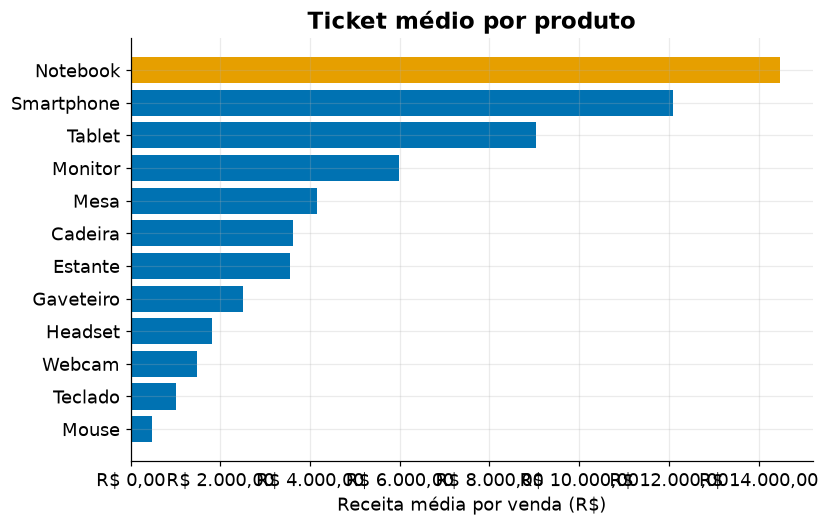

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))
cores = [COR_DESTAQUE if p == ticket_produto.idxmax() else COR_PRIMARIA for p in ticket_produto.index]
ax.barh(ticket_produto.index, ticket_produto.values, color=cores)
ax.set_title("Ticket médio por produto")
ax.set_xlabel("Receita média por venda (R$)")
ax.xaxis.set_major_formatter(lambda v, _: reais(v))
plt.show()


In [21]:
ticket_canal.to_frame("ticket_medio").apply(lambda col: col.map(reais))


,ticket_medio
canal_venda,
Marketplace,"R$ 4.794,47"
Online,"R$ 5.040,96"
Loja física,"R$ 5.113,70"


**Resultado:** o ticket médio geral é `R$ 5.003,23`, mas varia muito por produto — de `R$ 468` no Mouse a `R$ 14.483` no Notebook (quase 31x). Isso explica o ranking de faturamento visto antes: o número de vendas é parecido entre os 12 produtos (390 a 441 vendas cada, bem equilibrado), então Notebook não fatura mais porque vende com mais frequência — fatura mais porque cada venda vale muito mais. Por canal a diferença é pequena (de `R$ 4.794` no Marketplace a `R$ 5.114` na Loja física, ~7% de variação) — não é um fator relevante.


## Preço mais baixo puxa mais unidades por venda?
A ideia seria: produto mais barato, cliente compra mais unidades de uma vez. Vamos ver se isso aparece nos dados.


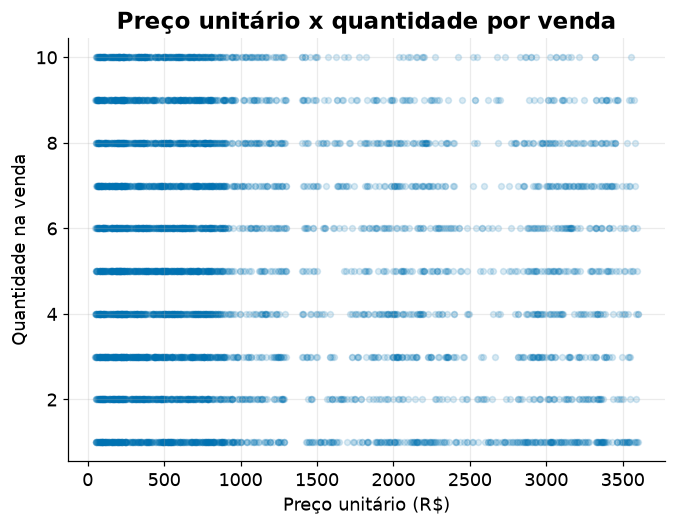

In [22]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["preco_unitario"], df["quantidade"], alpha=0.15, color=COR_PRIMARIA, s=15)
ax.set_title("Preço unitário x quantidade por venda")
ax.set_xlabel("Preço unitário (R$)")
ax.set_ylabel("Quantidade na venda")
plt.show()


In [23]:
df["preco_unitario"].corr(df["quantidade"])


np.float64(-0.10809206090881626)

**Resultado:** não tem relação relevante. A correlação é -0,11 — bem perto de zero, e a nuvem de pontos confirma: não há um formato claro, é só ruído espalhado. Produtos caros (Notebook, Smartphone, Tablet) vendem em média 4,5 a 4,9 unidades por venda contra 5,4 a 5,5 dos mais baratos — uma diferença pequena demais (menos de 1 unidade) pra sustentar a ideia de "mais barato, compra mais". Hipótese descartada.


## Conclusão

- A empresa faturou `R$ 25.016.139,62` no ano, com margem de `R$ 9.090.014,60` (36,3%).
- O faturamento cresce ao longo do ano e dá um salto forte em novembro/dezembro (quase o dobro do meio do ano) — sazonalidade real de fim de ano, não artefato de dado incompleto.
- **A margem percentual é praticamente constante (~36%) em toda categoria, região, canal e produto.** Não existe um corte mais "rentável" que o outro — a diferença entre eles é só volume e preço de venda.
- O faturamento é concentrado: `Eletrônicos` é 68% da receita, puxado por `Notebook`, `Smartphone` e `Tablet` (59% do total sozinhos); o `Sudeste` fatura quase o dobro do segundo colocado; e o canal `Online` é o maior (45%).
- **O motivo da concentração em produto não é frequência de venda, é preço:** os 12 produtos vendem em volume parecido (390 a 441 vendas cada), mas o ticket médio vai de `R$ 468` (Mouse) a `R$ 14.483` (Notebook) — quase 31x de diferença. Por canal, o ticket médio quase não varia (~7% entre o menor e o maior).
- Preço unitário não influencia quanto o cliente leva por venda (correlação -0,11, praticamente nula) — a hipótese de "produto mais barato, compra mais unidades" não se sustenta nesses dados.
- Achado de qualidade de dado: 154 vendas (3%) vieram sem região preenchida — mantidas na análise, só marcadas como "Não informado".

**Implicação prática:** como a margem já é uniforme, crescer o resultado financeiro aqui depende de vender mais unidades (principalmente dos itens de ticket alto, que já vendem na mesma frequência dos demais mas valem muito mais) ou melhorar a margem em si (hoje achatada em ~36% em tudo) — não de redirecionar vendas para um canal, região ou categoria supostamente mais lucrativa, porque essa diferença não existe nos dados.
